Xavier works best with thte tanh and he will work best on the relu 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../../data/ushape.csv')

In [3]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


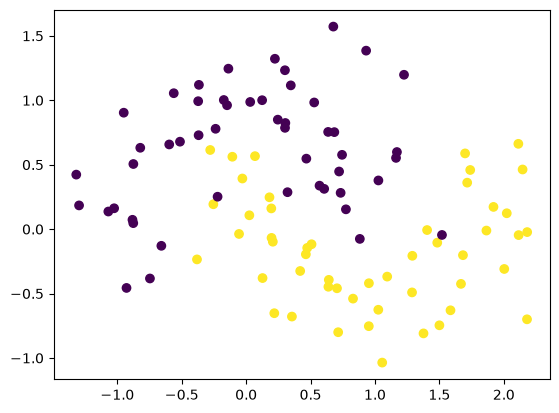

In [4]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [5]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [6]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

I0000 00:00:1795448262.973996    8222 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795448263.438893    8222 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795448265.738368    8222 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [ ]:
model = Sequential()

model.add(Dense(10,activation='tanh',input_dim=2))
model.add(Dense(10,activation='tanh'))
model.add(Dense(10,activation='tanh'))
model.add(Dense(10,activation='tanh'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

/home/foolmann/miniconda3/envs/ml312/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1795448267.410287    8222 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3617 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.get_weights()

[array([[-1.5574117 , -0.88458824,  0.7659551 ,  0.8025688 ,  0.2949927 ,
          2.1431973 ,  1.4731005 ,  1.7966597 , -0.42360613,  1.6259139 ],
        [ 0.12035054,  0.74633396,  0.7608218 , -0.46042308, -0.04018606,
         -0.7198151 , -1.4715341 ,  0.7303637 , -0.15266901,  1.7803098 ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.5103541 , -0.4075957 , -0.37888098,  0.48281193, -0.26846346,
         -0.27998558, -0.01393718, -0.3018489 ,  0.20712441,  0.47969377],
        [-0.5441215 ,  0.05265772, -0.28502244,  0.44445497,  0.09691674,
         -0.26804662,  0.46426117,  0.45258236,  0.34499896, -0.11634016],
        [ 0.2622044 , -0.26902315, -0.27822694,  0.34450012,  0.02080774,
          0.4330871 , -0.04077733, -0.4616234 ,  0.12548506, -0.48952323],
        [-0.00807279,  0.05617547, -0.26210138,  0.33182502,  0.04677022,
          0.24802852,  0.03824627,  0.33850968,  0.39686596, -0.16444746],
        [-0.45514

In [9]:
initial_weights = model.get_weights()

Using sqrt of (1 / fan_in) for the weights initialization 

In [ ]:
initial_weights[0] = np.random.randn(2,10)*np.sqrt(1/2)  # 2 inputs on first node 
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.random.randn(10,10)*np.sqrt(1/10) # 10 inputs on each node 
initial_weights[3] = np.zeros(model.get_weights()[3].shape)
initial_weights[4] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[5] = np.zeros(model.get_weights()[5].shape)
initial_weights[6] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[7] = np.zeros(model.get_weights()[7].shape)
initial_weights[8] = np.random.randn(10,1)*np.sqrt(1/10)
initial_weights[9] = np.zeros(model.get_weights()[9].shape)

In [11]:
model.set_weights(initial_weights)

In [12]:
model.get_weights()

[array([[-0.9344741 , -0.29940072, -0.56588954,  0.3672589 ,  0.1531938 ,
          1.0446745 , -0.2961805 , -0.42402607, -0.38085365, -0.5639894 ],
        [-0.02066464,  1.1027641 ,  0.11230069,  0.22430876, -0.6576789 ,
         -0.11079887, -0.36442906, -0.0758696 , -0.24863662,  0.20874669]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.15364182,  0.60398936,  0.562368  , -0.26766896,  0.5162678 ,
          0.5843313 , -0.3556601 ,  0.10367112,  0.257623  , -0.5179137 ],
        [-0.06737693,  0.03112021, -0.08812721, -0.00708806, -0.11249628,
          0.423936  , -0.00657873, -0.08291472, -0.05727519,  0.05992814],
        [ 0.01798384, -0.05479124, -0.07884586, -0.23400512,  0.08613272,
         -0.0156251 , -0.26306364,  0.33339226,  0.09777205,  0.19100274],
        [-0.12761126,  0.32692277,  0.25639236,  0.50689906, -0.13626045,
          0.14603017,  0.10236165,  0.5804472 ,  0.34034884, -0.4804876 ],
        [ 0.16791

In [13]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [14]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100


I0000 00:00:1795448269.803282    8325 service.cc:153] XLA service 0x7f2e700071a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795448269.803334    8325 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1795448269.851215    8325 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795448270.138978    8325 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1795448270.150262    8325 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2079__.11


1/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.6562 - loss: 0.6774

I0000 00:00:1795448271.076684    8325 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1795448271.267570    8319 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2079__.11


3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 863ms/step - accuracy: 0.6375 - loss: 0.6758 - val_accuracy: 0.8000 - val_loss: 0.6462
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6750 - loss: 0.6625 - val_accuracy: 0.8500 - val_loss: 0.6292
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7000 - loss: 0.6509 - val_accuracy: 0.8500 - val_loss: 0.6116
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7000 - loss: 0.6389 - val_accuracy: 0.8500 - val_loss: 0.5945
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7125 - loss: 0.6267 - val_accuracy: 0.8500 - val_loss: 0.5782
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7125 - loss: 0.6151 - val_accuracy: 0.8500 - val_loss: 0.5626
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7125 - loss: 0.6031 - val_accuracy: 0.8500 - val_loss: 0.5474
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7125 - loss: 0.5921 - val_accuracy: 0.8500 - val_loss: 0.5328
Epo

In [15]:
model.get_weights()

[array([[-0.74378383, -0.400772  , -0.4856084 ,  0.414694  ,  0.20861615,
          1.1236522 , -0.22294252, -0.43019876, -0.52238214, -0.48820564],
        [ 0.09636811,  1.1790398 ,  0.07376634,  0.14899099, -0.6229532 ,
         -0.21154442, -0.46992517, -0.17346814, -0.42367968,  0.32661328]],
       dtype=float32),
 array([ 0.00580608, -0.00155768, -0.14468268,  0.07201803,  0.02381141,
        -0.1080033 ,  0.07776164,  0.00965307, -0.10834317,  0.06032472],
       dtype=float32),
 array([[ 1.52796686e-01,  5.31511307e-01,  5.28529882e-01,
         -2.42677227e-01,  4.88661140e-01,  5.91266215e-01,
         -3.49528641e-01,  8.36669356e-02,  2.16394141e-01,
         -5.20836711e-01],
        [-1.66135952e-01, -3.57170254e-02,  2.60357367e-04,
         -1.16381876e-01, -2.15520784e-01,  5.44592083e-01,
         -8.90239179e-02, -1.76957622e-01, -1.73851505e-01,
         -4.52058204e-02],
        [-3.01296487e-02, -1.41965389e-01, -6.67039379e-02,
         -2.61841416e-01,  1.90789

<Axes: >

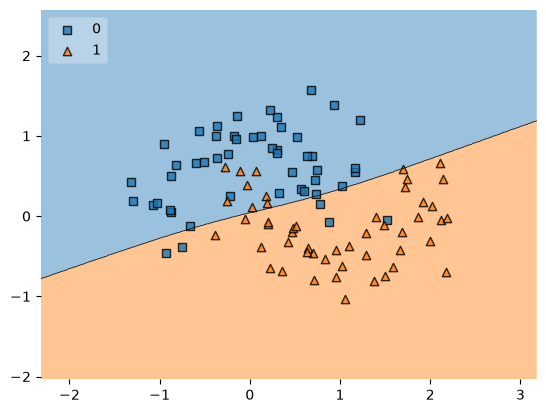

In [16]:
# from mlxtend.plotting import plot_decision_regions
# plot_decision_regions(X,y.astype('int'), clf=model, legend=2)
import numpy as np
from mlxtend.plotting import plot_decision_regions

class KerasClassifier:
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        predictions = self.model.predict(X, verbose=0)
        return (predictions.ravel() >= 0.5).astype(int)


# Convert labels to integers
y = y.astype(int)

# Wrap the model
clf = KerasClassifier(model)

# Plot decision regions
plot_decision_regions(X, y, clf=clf, legend=2)

In [17]:
(np.random.randn(10,10)*0.01).min()

np.float64(-0.02525709214084018)

In [18]:
(np.random.randn(10,10)*0.01).max()

np.float64(0.024674818939171336)